# F11: too few bands (implemented: diagnostic and warning)

**Finding** (`notes/theory_audit.md`, F11): when `elec-n-bands` is close to the number of orbitals, some
orbital combinations (typically σ*) lie above every computed band at some k-points. The Löwdin step (and
$S^{-1}$ in the non-orthogonal basis) then rebuilds those orbitals from bands that barely contain them, and pair
spectra are not converged in the number of bands. Nothing warned about this.

**Fix:** `ElecData.orbital_span_t` gives, per state, the smallest eigenvalue of the band-space overlap
$S_t = P_t^\dagger P_t$ over its largest. With ortho-orbital projections that is the fraction of the
worst-represented orbital combination the bands hold. Loading a calculation warns when any state is below
`SPAN_WARN_RTOL` = 1e-4, and names the orbitals involved. That warning also reports the directions the Löwdin
step dropped (F10). No numbers change, so there is no legacy switch.

The fixtures here come in pairs that differ only in `elec-n-bands`. The full band-count series behind the
threshold is in the notes (F11 record) and summarized at the end. Figures are saved to `figures/`. The last
cell holds the tests.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixcompare import *
from crawfish.core.elecdata import ElecData, SPAN_WARN_RTOL
from crawfish.funcs import get_ipcohp

FEW_C, MORE_C = "#eb6834", "#2a78d6"  # categorical slots 2 and 1 of the default palette
D = Path(EXAMPLE_CALC_DIRS_DIR)
RUNS = {"N2, 10 bands": "N2_nospin_10bands", "N2, 15 bands": "N2_nospin",
        "graphene, 20 bands": "graphene_zspin_tr", "graphene, 30 bands": "graphene_zspin_tr_30bands",
        "graphene_1x1, 8 bands": "graphene_1x1"}


def load(name):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        edata = ElecData(D / name)
    return edata, [str(w.message) for w in caught if "Too few bands" in str(w.message)]


loaded = {label: load(name) for label, name in RUNS.items()}

## Band-space overlap per state

The smallest eigenvalue of $S_t$ over its largest, for every state. A missing combination sits at float32
noise (1e-8 to 1e-16), far below anything a spanned orbital gives.

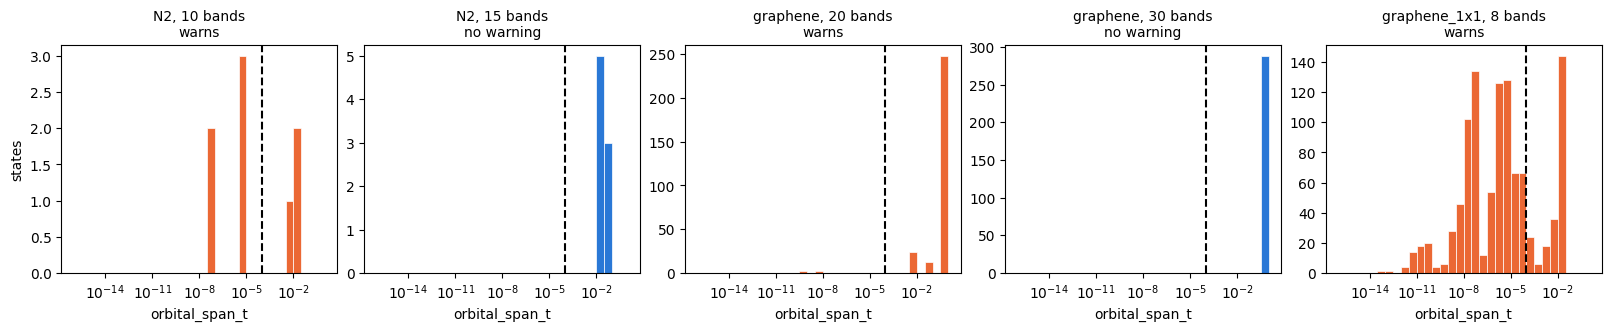

,states,below 1e-4,smallest,warning
"N2, 10 bands",8,5,0.0,Too few bands: at 5 of 8 states (62.5% of the ...
"N2, 15 bands",8,0,0.021732,
"graphene, 20 bands",288,4,0.0,Too few bands: at 4 of 288 states (1.4% of the...
"graphene, 30 bands",288,0,0.932738,
"graphene_1x1, 8 bands",1058,830,0.0,Too few bands: at 830 of 1058 states (78.4% of...


In [2]:
fig, axes = plt.subplots(1, len(loaded), figsize=(16, 3.2), sharex=True, layout="constrained")
bins = np.logspace(-16, 0, 33)
for ax, (label, (edata, msgs)) in zip(axes, loaded.items()):
    ax.hist(np.clip(edata.orbital_span_t, 1e-16, None), bins=bins, color=FEW_C if msgs else MORE_C,
            edgecolor="white", linewidth=0.5)
    ax.axvline(SPAN_WARN_RTOL, color="black", linewidth=1.5, linestyle="--")
    ax.set_xscale("log")
    ax.set_title(f"{label}\n{'warns' if msgs else 'no warning'}", fontsize=10)
    ax.set_xlabel("orbital_span_t")
axes[0].set_ylabel("states")
savefig(fig, "F11_orbital_span")
plt.show()

summary = pd.DataFrame({label: {"states": edata.nstates,
                                "below 1e-4": int(np.sum(edata.orbital_span_t < SPAN_WARN_RTOL)),
                                "smallest": float(edata.orbital_span_t.min()),
                                "warning": msgs[0].split(" Pair spectra")[0] if msgs else ""}
                        for label, (edata, msgs) in loaded.items()}).T
summary

## Do the warned runs differ from runs with more bands?

N1–N2 IpCOHP for N2, and the mean IpCOHP of C1's three nearest C2 images for graphene, computed from the fixture
pairs. The figure adds the band counts that weren't kept as fixtures.

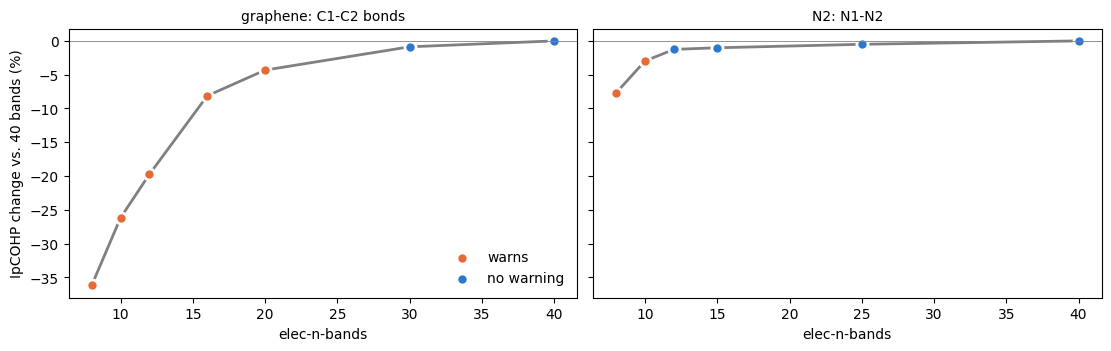

,fewer bands (warns),more bands (quiet),change (%)
N2,-0.849699,-0.866800,-1.972956
graphene,-0.501261,-0.519316,-3.476697


In [3]:
def bond_ipcohp(edata):
    st = edata.structure
    d = {R: np.linalg.norm(st.lattice.get_cartesian_coords(st.frac_coords[1] + np.array(R) - st.frac_coords[0]))
         for R in [(a, b, 0) for a in (-1, 0, 1) for b in (-1, 0, 1)]}
    nearest = sorted(d, key=d.get)[:3]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return float(np.mean([last_value(get_ipcohp(edata, idcs1=0, idcs2=1, image=list(R))) for R in nearest]))

pairs = {"N2": ("N2, 10 bands", "N2, 15 bands"), "graphene": ("graphene, 20 bands", "graphene, 30 bands")}
rows = {}
for system, (few, more) in pairs.items():
    f = (lambda ed: last_value(get_ipcohp(ed, idcs1=0, idcs2=1))) if system == "N2" else bond_ipcohp
    rows[system] = {"fewer bands (warns)": f(loaded[few][0]), "more bands (quiet)": f(loaded[more][0])}
conv = pd.DataFrame(rows).T
conv["change (%)"] = 100 * (conv["fewer bands (warns)"] / conv["more bands (quiet)"] - 1)

# The full series run for F11 (only the pairs above are kept as fixtures); values from notes/theory_audit.md
SERIES = {"graphene: C1-C2 bonds": {8: (-0.33422, True), 10: (-0.38674, True), 12: (-0.42051, True),
                                    16: (-0.48130, True), 20: (-0.50126, True), 30: (-0.51932, False),
                                    40: (-0.52391, False)},
          "N2: N1-N2": {8: (-0.80838, True), 10: (-0.84970, True), 12: (-0.86473, False), 15: (-0.86680, False),
                        25: (-0.87132, False), 40: (-0.87572, False)}}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True, layout="constrained")
for ax, (title, series) in zip(axes, SERIES.items()):
    nb = np.array(sorted(series))
    rel = np.array([100 * (series[n][0] / series[40][0] - 1) for n in nb])
    warns = np.array([series[n][1] for n in nb])
    ax.plot(nb, rel, color="gray", linewidth=2, zorder=1)
    ax.scatter(nb[warns], rel[warns], s=64, color=FEW_C, edgecolor="white", linewidth=2, zorder=2, label="warns")
    ax.scatter(nb[~warns], rel[~warns], s=64, color=MORE_C, edgecolor="white", linewidth=2, zorder=2,
               label="no warning")
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("elec-n-bands")
axes[0].set_ylabel("IpCOHP change vs. 40 bands (%)")
axes[0].legend(frameon=False, loc="lower right")
savefig(fig, "F11_band_convergence")
plt.show()
conv

## The full band-count series (from the notes)

Run locally for F11 with only `elec-n-bands` changed (only the pairs above are kept as fixtures; the figure plots
the orthonormal-projection rows). IpCOHP in Ha; "warns" is the new warning. Graphene is the mean over the three
nearest bonds, N2 is N1–N2.

| system | bands | IpCOHP | vs. 40 bands | warns |
|---|---|---|---|---|
| graphene (ortho) | 8 | −0.334 | −36% | yes |
| | 12 | −0.421 | −20% | yes |
| | 16 | −0.481 | −8.1% | yes |
| | 20 | −0.501 | −4.3% | yes |
| | 30 | −0.519 | −0.9% | no |
| | 40 | −0.524 | | no |
| N2 (ortho) | 8 | −0.808 | −7.7% | yes |
| | 10 | −0.850 | −3.0% | yes |
| | 12 | −0.865 | −1.3% | no |
| | 15 | −0.867 | −1.0% | no |
| | 40 | −0.876 | | no |
| graphene (non-orthogonal, `los_orbs=False`) | 8, 12 | +16, +7 (nonsense) | | yes |
| | 20 | −0.233 | −15% | yes |
| | 40 | −0.273 | | no |

N2's σ* combination is still only partly spanned at 40 bands (box states crowd in below it), but it barely
enters the occupied bonding states, so N2 converges much faster than graphene.

## Tests

In [4]:
warned = {label: bool(msgs) for label, (_, msgs) in loaded.items()}
assert warned == {"N2, 10 bands": True, "N2, 15 bands": False, "graphene, 20 bands": True,
                  "graphene, 30 bands": False, "graphene_1x1, 8 bands": True}
assert "mostly N px, N s." in loaded["N2, 10 bands"][1][0]
assert "mostly C px, C py." in loaded["graphene, 20 bands"][1][0]
assert summary.loc["graphene, 30 bands", "smallest"] > 0.9
assert abs(conv.loc["graphene", "change (%)"]) > 3 and abs(conv.loc["N2", "change (%)"]) > 1.5
print("All F11 checks passed.")

All F11 checks passed.
